<a href="https://colab.research.google.com/github/gchekwemoi/OOP-python-assignment/blob/main/project4_rainfall.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [14]:
# Portable setup for Anaconda/Jupyter and Google Colab
from pathlib import Path
import os
import sys
import subprocess

repo = Path.cwd().resolve()
if not (repo / "src").is_dir():
    colab_repo = Path("/content/OOP-python-assignment")
    if colab_repo.is_dir():
        repo = colab_repo
    elif "google.colab" in sys.modules or os.environ.get("COLAB_RELEASE_TAG"):
        subprocess.run(
            ["git", "clone", "https://github.com/gchekwemoi/OOP-python-assignment.git",
             str(colab_repo)], check=True
        )
        repo = colab_repo
    else:
        raise FileNotFoundError(
            "Open Jupyter from the OOP-python-assignment repository folder, "
            "which must contain the src/ and tests/ directories."
        )
os.chdir(repo)
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
print("Project directory:", repo)

# Check the project's automated tests
subprocess.run([sys.executable, "-m", "pytest", "tests/test_rainfall.py", "-v"], check=True)


/content/OOP-python-assignment
============================= test session starts ==============================
platform linux -- Python 3.13.16, pytest-8.4.2, pluggy-1.6.0 -- /usr/bin/python3
cachedir: .pytest_cache
rootdir: /content/OOP-python-assignment
plugins: anyio-4.15.1, platformdirs-4.12.2, langsmith-0.14.2, typeguard-4.6.0
collected 10 items                                                             

tests/test_rainfall.py::test_region_annual_total PASSED                  [ 10%]
tests/test_rainfall.py::test_region_monthly_mean PASSED                  [ 20%]
tests/test_rainfall.py::test_invalid_rainfall PASSED                     [ 30%]
tests/test_rainfall.py::test_negative_rainfall PASSED                    [ 40%]
tests/test_rainfall.py::test_crop_suitability PASSED                     [ 50%]
tests/test_rainfall.py::test_invalid_crop_thresholds PASSED              [ 60%]
tests/test_rainfall.py::test_cosine_similarity PASSED                    [ 70%]
tests/test_rainfall.py::

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.rainfall import Region
from src.crop_rule import CROP_RULES
from src.rainfall_analysis import RainfallAnalyser

# Monthly rainfall in millimetres (Jan-Dec)
# Illustrative data provided in the assignment
kampala = Region("Kampala", [
    120, 140, 180, 200, 220, 180,
    90, 70, 60, 100, 110, 130
])

gulu = Region("Gulu", [
    8, 25, 75, 160, 190, 145,
    170, 215, 175, 150, 60, 15
])

mbarara = Region("Mbarara", [
    70, 85, 120, 140, 90, 25,
    20, 55, 100, 125, 120, 90
])

regions = [kampala, gulu, mbarara]

# Create rainfall analyser object
analyser = RainfallAnalyser(regions)

# Calculate descriptive statistics
rainfall_summary = []

for region in regions:
    rainfall_summary.append({
        "Region": region.name,
        "Annual Rainfall (mm)": region.annual_total(),
        "Monthly Mean (mm)": region.monthly_mean(),
        "Wettest Month": region.wettest_month(),
        "Driest Month": region.driest_month(),
        "CV (%)": region.coefficient_of_variation()
    })

summary_df = pd.DataFrame(rainfall_summary)

print("RAINFALL ANALYSIS FOR UGANDAN REGIONS")
display(summary_df.round(2))


RAINFALL ANALYSIS FOR UGANDAN REGIONS


,Region,Annual Rainfall (mm),Monthly Mean (mm),Wettest Month,Driest Month,CV (%)
0,Kampala,1600.0,133.33,May,September,38.82
1,Gulu,1388.0,115.67,August,January,64.15
2,Mbarara,1040.0,86.67,April,July,44.37


In [5]:

# Calculate rainfall similarity and distance matrices
comparison = analyser.similarity_matrices()

names = comparison["region_names"]

for measure, matrix in comparison["matrices"].items():

    result_df = pd.DataFrame(
        matrix,
        index=names,
        columns=names
    )

    print(f"\n{measure.upper()}")
    display(result_df.round(3))

# Verify our cosine formula against SciPy
print("\nCosine formula matches SciPy:",
      analyser.validate_cosine(
          kampala.rainfall,
          gulu.rainfall
      ))

# Detect rainy-season peaks
season_results = []

for region in regions:
    season = analyser.detect_rainy_seasons(region)

    season_results.append({
        "Region": region.name,
        "Peak Months": ", ".join(season["peak_months"]),
        "Detected Pattern": season["pattern"]
    })

print("\nRAINFALL SEASON DETECTION")
display(pd.DataFrame(season_results))



COSINE SIMILARITY


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000



PEARSON CORRELATION


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000



EUCLIDEAN DISTANCE


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.4
Gulu,315.268,0.000,312.8
Mbarara,250.400,312.800,0.0



Cosine formula matches SciPy: True

RAINFALL SEASON DETECTION


,Region,Peak Months,Detected Pattern
0,Kampala,May,Unimodal
1,Gulu,"May, August",Bimodal
2,Mbarara,"April, October",Bimodal


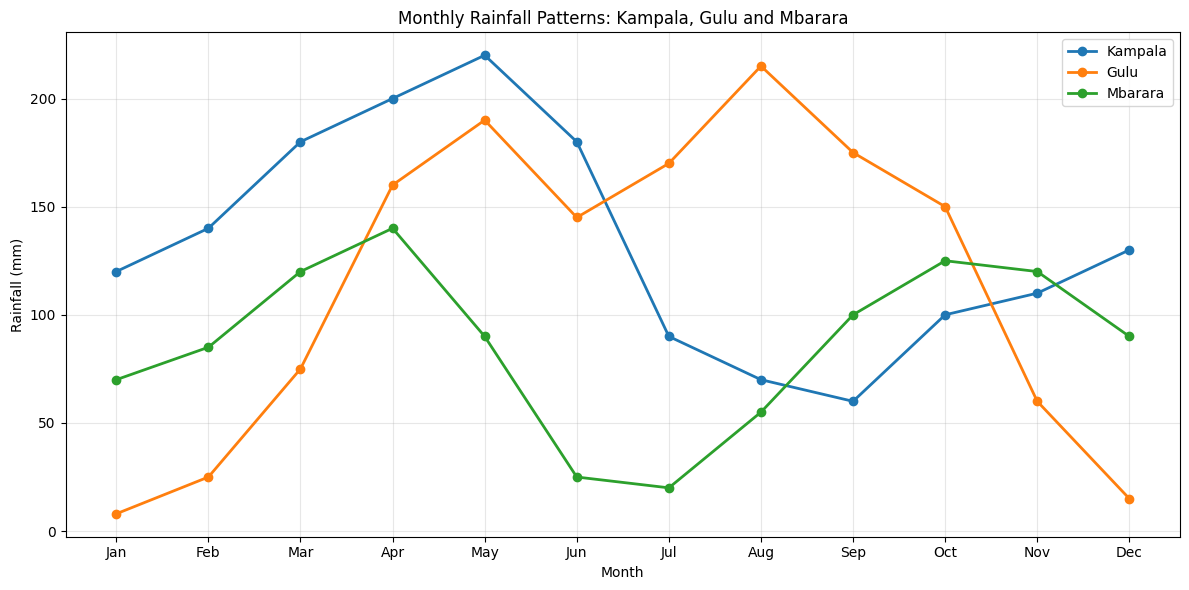

In [6]:

import matplotlib.pyplot as plt
import numpy as np

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 6))

for region in regions:
    plt.plot(
        months,
        region.rainfall,
        marker="o",
        linewidth=2,
        label=region.name
    )

plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.title("Monthly Rainfall Patterns: Kampala, Gulu and Mbarara")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


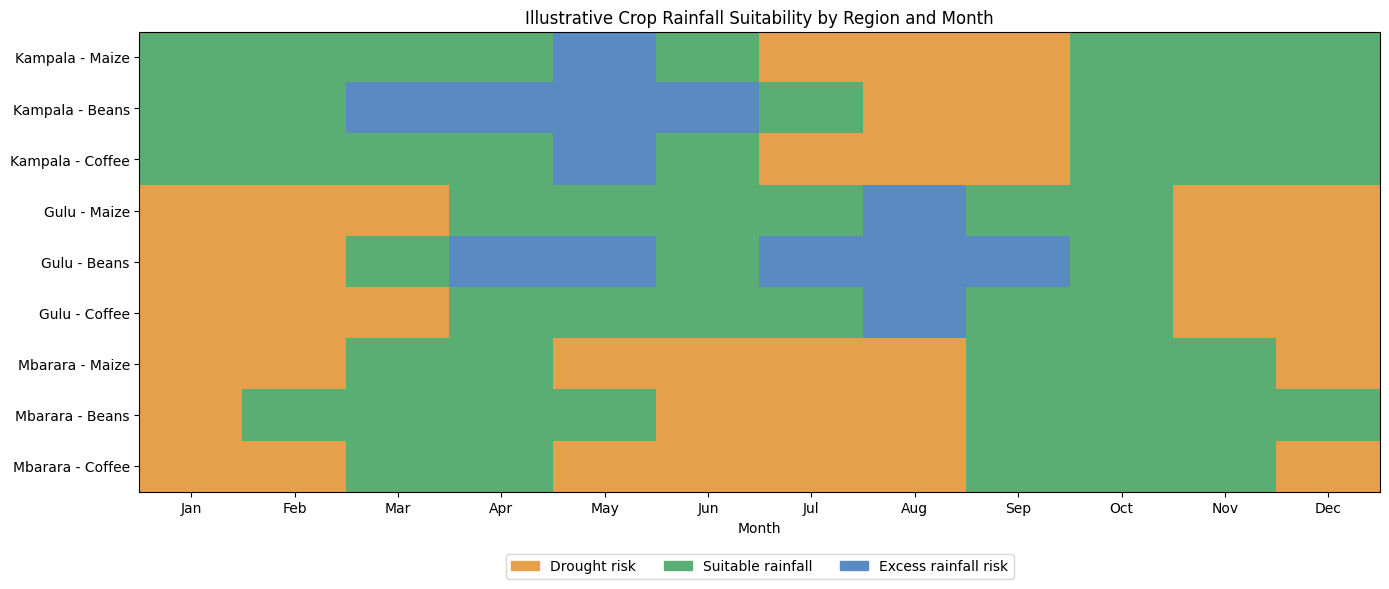

In [7]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

# Numerical categories for the heatmap
categories = {
    "Drought risk": 0,
    "Suitable rainfall": 1,
    "Excess rainfall risk": 2
}

# Build classifications for each crop and region
heatmap_data = []
row_labels = []

for region in regions:
    for crop in CROP_RULES:
        classifications = crop.classify_year(
            region.rainfall
        )

        heatmap_data.append([
            categories[value]
            for value in classifications
        ])

        row_labels.append(
            f"{region.name} - {crop.name}"
        )

heatmap_data = np.array(heatmap_data)

# Use three distinct colours
cmap = ListedColormap([
    "#E6A04B",  # Drought risk
    "#5BAE73",  # Suitable rainfall
    "#598AC2"   # Excess rainfall risk
])

fig, ax = plt.subplots(figsize=(14, 6))

ax.imshow(
    heatmap_data,
    cmap=cmap,
    vmin=-0.5,
    vmax=2.5,
    aspect="auto"
)

ax.set_xticks(range(12))
ax.set_xticklabels(months)

ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)

ax.set_xlabel("Month")
ax.set_title("Illustrative Crop Rainfall Suitability by Region and Month")

# Add a legend
legend_items = [
    Patch(color="#E6A04B", label="Drought risk"),
    Patch(color="#5BAE73", label="Suitable rainfall"),
    Patch(color="#598AC2", label="Excess rainfall risk")
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

plt.tight_layout()
plt.show()


## Farmer Advisory Note: Maize Growing in Gulu

Farmers in Gulu should consider planting maize at the beginning of the main rainy season, when sufficient moisture is available for germination and crop development.

Based on the illustrative rainfall data, rainfall increases from 75 mm in March to 160 mm in April and 190 mm in May. Under the simplified crop-suitability rules used in this project, April and May have suitable monthly rainfall for maize.

Farmers could therefore consider planting around late March or early April, provided rainfall has become consistent and the soil has adequate moisture. June also records 145 mm, which may support crop development.

However, rainfall alone cannot determine the best planting date. Farmers should consider soil conditions, the maize variety, seasonal weather forecasts and local agricultural extension advice before planting.

The rainfall figures used in this analysis are illustrative and should not be treated as actual forecasts or definitive planting recommendations.

Extension: Analysis of Real Rainfall Data (2015–2024).


In [11]:

# PROJECT 4 EXTENSION: REAL RAINFALL DATA (2015–2024)
# Source: NASA POWER

import requests
import numpy as np
import pandas as pd
import calendar

# Approximate city-centre coordinates (latitude, longitude)
locations = {
    "Kampala": (0.3476, 32.5825),
    "Gulu": (2.7746, 32.2990),
    "Mbarara": (-0.6072, 30.6545)
}

def download_rainfall(region, latitude, longitude):
    """Download 10 years of monthly rainfall from NASA POWER."""

    url = "https://power.larc.nasa.gov/api/temporal/monthly/point"

    params = {
        "parameters": "PRECTOTCORR_SUM",
        "community": "AG",
        "longitude": longitude,
        "latitude": latitude,
        "start": 2015,
        "end": 2024,
        "format": "JSON"
    }

    response = requests.get(
        url,
        params=params,
        timeout=90
    )

    response.raise_for_status()

    data = response.json()

    rainfall = data["properties"]["parameter"]["PRECTOTCORR_SUM"]

    records = []

    for period, value in rainfall.items():

        # NASA POWER uses YYYYMM for monthly records.
        # Annual summary records (YYYY13) must be excluded.
        if len(period) != 6 or not period.isdigit():
            continue

        year = int(period[:4])
        month = int(period[4:6])

        if month < 1 or month > 12:
            continue

        if value is None or not np.isfinite(value) or value < 0:
            raise ValueError(
                f"Missing or invalid rainfall: {region}, {period}"
            )

        records.append({
            "Region": region,
            "Year": year,
            "Month": month,
            "Month_Name": calendar.month_abbr[month],
            "Rainfall_mm": float(value)
        })

    if len(records) != 120:
        raise ValueError(
            f"{region}: Expected 120 monthly records, "
            f"but received {len(records)}."
        )

    return records


# Download rainfall for the three regions
all_records = []

for name, (latitude, longitude) in locations.items():

    print(f"Downloading rainfall data for {name}...")

    records = download_rainfall(
        name,
        latitude,
        longitude
    )

    all_records.extend(records)


# Create a DataFrame
real_rainfall = pd.DataFrame(all_records)

# Sort chronologically
real_rainfall = real_rainfall.sort_values(
    ["Region", "Year", "Month"]
).reset_index(drop=True)

# Save to CSV
real_rainfall.to_csv(
    "uganda_real_rainfall_2015_2024.csv",
    index=False
)

# Display results
print("\nREAL RAINFALL DATA DOWNLOADED SUCCESSFULLY")
print("---------------------------------------")

print("Regions:", real_rainfall["Region"].nunique())

print("Years:", real_rainfall["Year"].nunique())

print("Total observations:", len(real_rainfall))

print("\nObservations per region:")
print(real_rainfall.groupby("Region").size())

print("\nFirst 12 observations:")
display(real_rainfall.head(12))

# Annual rainfall totals
annual_rainfall = (
    real_rainfall
    .groupby(["Region", "Year"])["Rainfall_mm"]
    .sum()
    .reset_index(name="Annual_Rainfall_mm")
)

print("\nANNUAL RAINFALL TOTALS (2015–2024)")
display(
    annual_rainfall.pivot(
        index="Year",
        columns="Region",
        values="Annual_Rainfall_mm"
    ).round(2)
)



REAL RAINFALL DATA DOWNLOADED SUCCESSFULLY
---------------------------------------
Regions: 3
Years: 10
Total observations: 360

Observations per region:
Region
Gulu       120
Kampala    120
Mbarara    120
dtype: int64

First 12 observations:


,Region,Year,Month,Month_Name,Rainfall_mm
0,Gulu,2015,1,Jan,0.41
1,Gulu,2015,2,Feb,9.69
2,Gulu,2015,3,Mar,38.02
3,Gulu,2015,4,Apr,145.58
4,Gulu,2015,5,May,236.48
5,Gulu,2015,6,Jun,137.89
6,Gulu,2015,7,Jul,102.47
7,Gulu,2015,8,Aug,117.82
8,Gulu,2015,9,Sep,94.47
9,Gulu,2015,10,Oct,271.32



ANNUAL RAINFALL TOTALS (2015–2024)


Region,Gulu,Kampala,Mbarara
Year,,,
2015,1396.14,1840.75,1119.56
2016,1108.85,1212.18,879.62
2017,1471.54,1322.63,1128.36
2018,1143.95,1413.46,1145.43
2019,1532.24,1724.06,1493.57
2020,2128.29,1670.92,1656.17
2021,1151.23,1107.21,1452.77
2022,1276.90,1441.18,1904.19
2023,1621.26,1791.83,1248.17


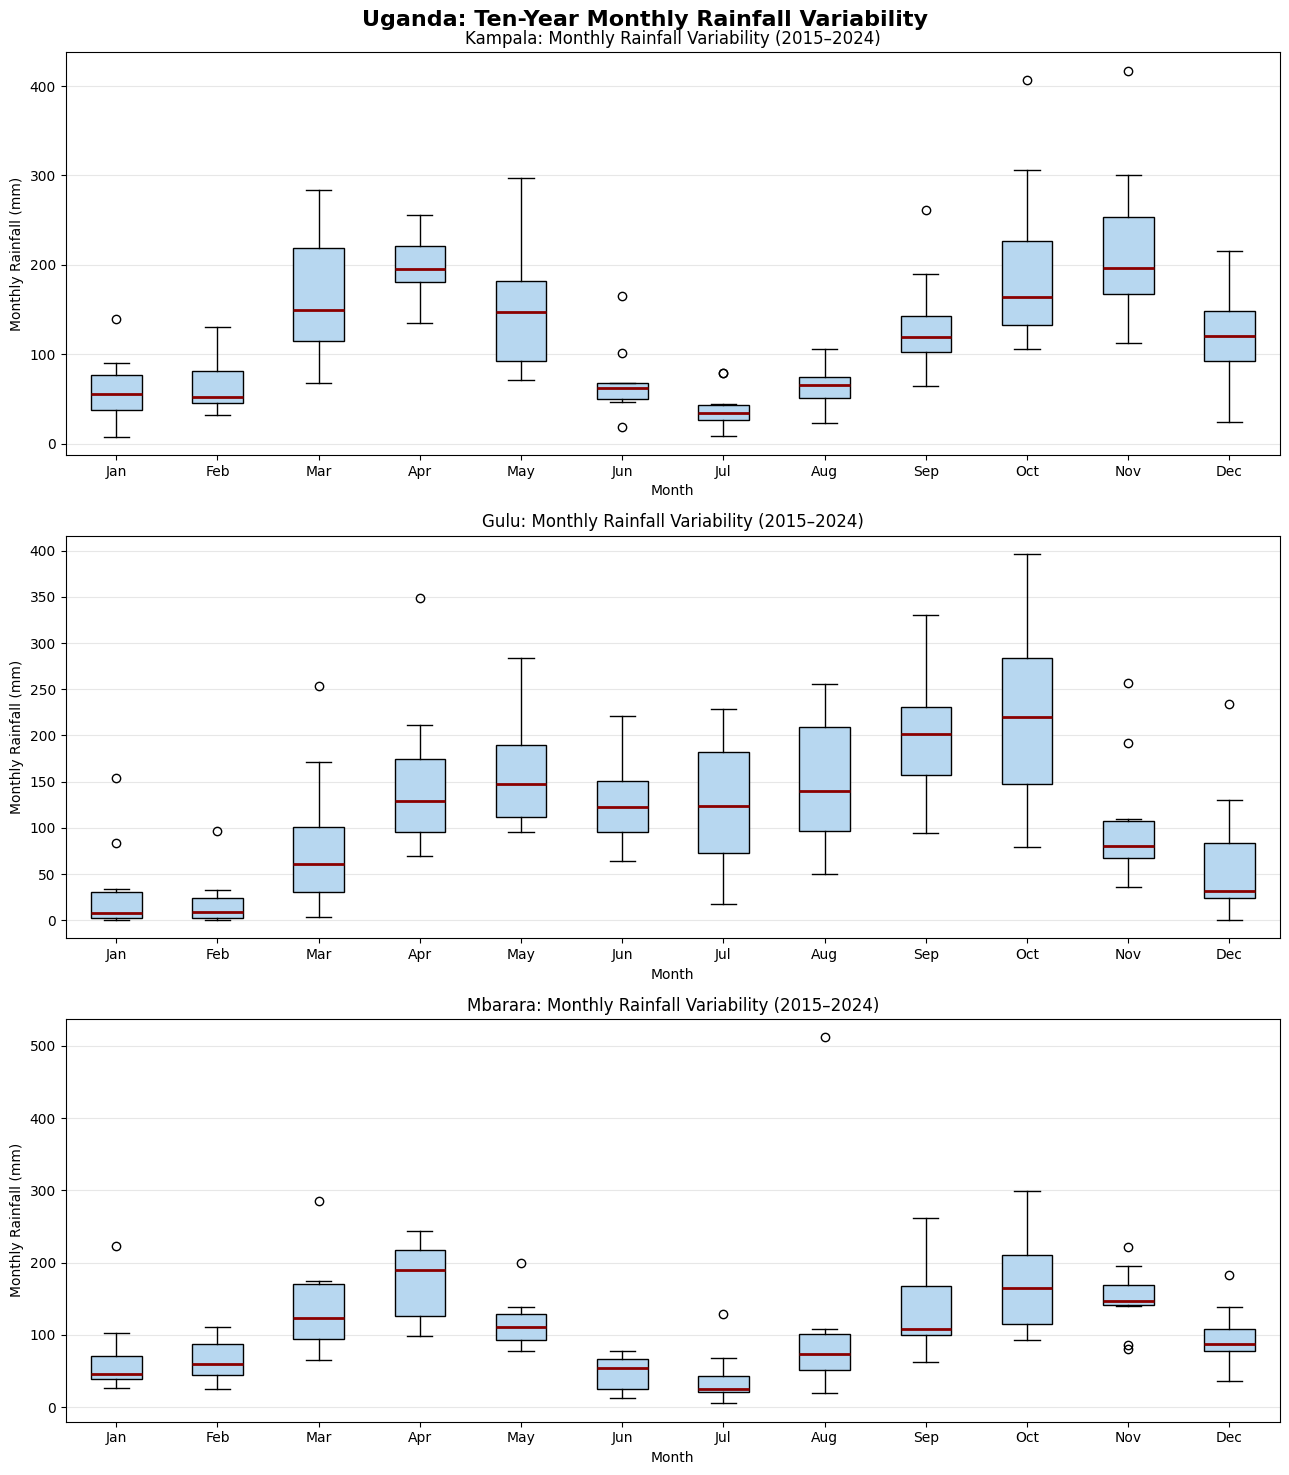

AVERAGE MONTHLY RAINFALL (2015–2024)


Region,Gulu,Kampala,Mbarara
Jan,31.52,60.27,68.18
Feb,19.60,68.07,63.27
Mar,81.51,163.76,138.73
Apr,150.30,199.20,175.92
May,160.62,152.20,116.78
Jun,131.71,69.69,47.36
Jul,125.70,40.03,39.27
Aug,151.82,66.17,113.10
Sep,200.93,133.00,138.42
Oct,221.41,195.02,171.97



TEN-YEAR ANNUAL RAINFALL SUMMARY


,Average Annual Rainfall (mm),Minimum Annual Rainfall (mm),Maximum Annual Rainfall (mm),Annual Standard Deviation (mm)
Region,,,,
Gulu,1441.79,1108.85,2128.29,306.79
Kampala,1489.50,1107.21,1840.75,252.94
Mbarara,1316.53,879.62,1904.19,305.81


In [12]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Confirm the real rainfall dataset is available
assert len(real_rainfall) == 360, "Expected 360 monthly observations"

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

regions_list = ["Kampala", "Gulu", "Mbarara"]

# Create monthly box plots for each region
fig, axes = plt.subplots(3, 1, figsize=(13, 15))

for ax, region_name in zip(axes, regions_list):

    region_data = real_rainfall[
        real_rainfall["Region"] == region_name
    ]

    # Each box contains 10 observations for that month
    monthly_values = [
        region_data.loc[
            region_data["Month"] == month,
            "Rainfall_mm"
        ].values
        for month in range(1, 13)
    ]

    ax.boxplot(
        monthly_values,
        tick_labels=months,
        patch_artist=True,
        boxprops={"facecolor": "#B7D7F0"},
        medianprops={"color": "darkred", "linewidth": 2}
    )

    ax.set_title(
        f"{region_name}: Monthly Rainfall Variability (2015–2024)"
    )
    ax.set_xlabel("Month")
    ax.set_ylabel("Monthly Rainfall (mm)")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Uganda: Ten-Year Monthly Rainfall Variability",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


# Calculate average monthly rainfall for each region
monthly_averages = (
    real_rainfall
    .groupby(["Region", "Month"])["Rainfall_mm"]
    .mean()
    .unstack(0)
)

monthly_averages.index = months

print("AVERAGE MONTHLY RAINFALL (2015–2024)")
display(monthly_averages.round(2))


# Summarise annual rainfall variability
annual_summary = (
    annual_rainfall
    .groupby("Region")["Annual_Rainfall_mm"]
    .agg(["mean", "min", "max", "std"])
    .round(2)
)

annual_summary.columns = [
    "Average Annual Rainfall (mm)",
    "Minimum Annual Rainfall (mm)",
    "Maximum Annual Rainfall (mm)",
    "Annual Standard Deviation (mm)"
]

print("\nTEN-YEAR ANNUAL RAINFALL SUMMARY")
display(annual_summary)


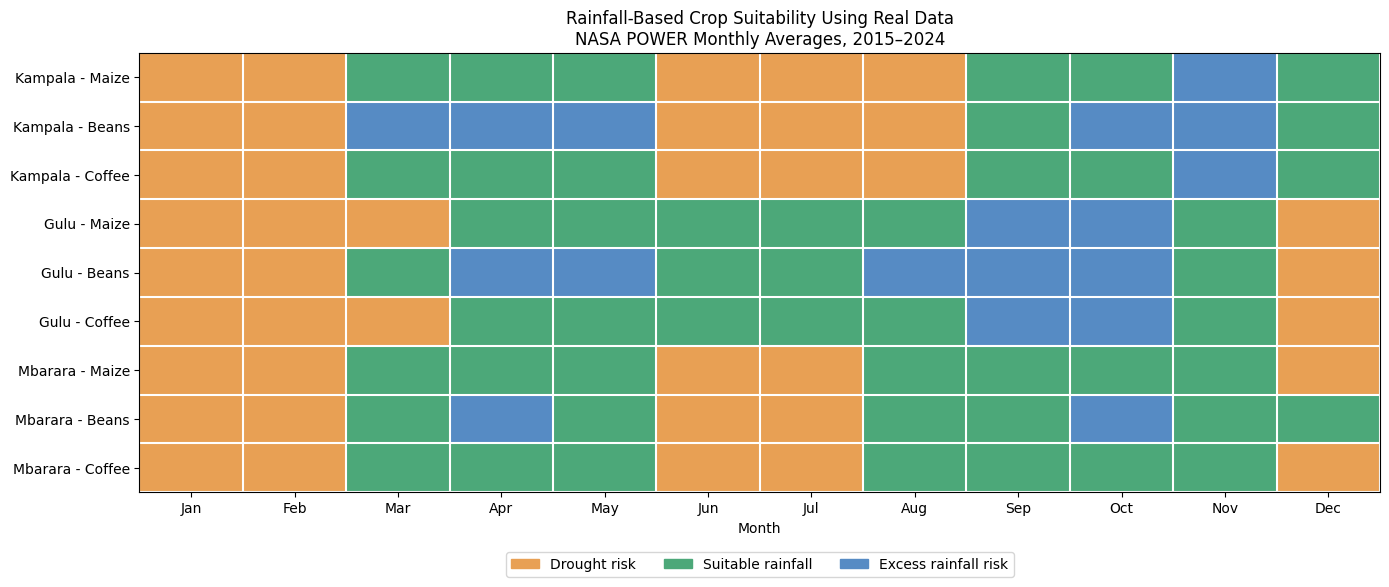

MONTHS WITH SUITABLE AVERAGE RAINFALL
-------------------------------------


,Region,Crop,Months with suitable rainfall
0,Kampala,Maize,"Mar, Apr, May, Sep, Oct, Dec"
1,Kampala,Beans,"Sep, Dec"
2,Kampala,Coffee,"Mar, Apr, May, Sep, Oct, Dec"
3,Gulu,Maize,"Apr, May, Jun, Jul, Aug, Nov"
4,Gulu,Beans,"Mar, Jun, Jul, Nov"
5,Gulu,Coffee,"Apr, May, Jun, Jul, Aug, Nov"
6,Mbarara,Maize,"Mar, Apr, May, Aug, Sep, Oct, Nov"
7,Mbarara,Beans,"Mar, May, Aug, Sep, Nov, Dec"
8,Mbarara,Coffee,"Mar, Apr, May, Aug, Sep, Oct, Nov"


In [13]:

# REAL-DATA PLANTING-SEASON SUITABILITY HEATMAP
# NASA POWER rainfall data, 2015–2024

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from src.crop_rule import CROP_RULES

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

region_names = ["Kampala", "Gulu", "Mbarara"]

# Calculate 10-year average rainfall for each calendar month
monthly_climatology = (
    real_rainfall
    .groupby(["Region", "Month"])["Rainfall_mm"]
    .mean()
    .unstack("Month")
    .reindex(index=region_names, columns=range(1, 13))
)

# Encode the three suitability categories
category_codes = {
    "Drought risk": 0,
    "Suitable rainfall": 1,
    "Excess rainfall risk": 2
}

heatmap_values = []
row_labels = []

for region_name in region_names:
    rainfall_values = monthly_climatology.loc[
        region_name
    ].to_numpy()

    for crop in CROP_RULES:
        classifications = crop.classify_year(
            rainfall_values
        )

        heatmap_values.append([
            category_codes[value]
            for value in classifications
        ])

        row_labels.append(
            f"{region_name} - {crop.name}"
        )

heatmap_values = np.array(heatmap_values)

# Create the planting-season heatmap
cmap = ListedColormap([
    "#E8A054",  # Drought risk
    "#4CA879",  # Suitable rainfall
    "#568BC4"   # Excess rainfall risk
])

fig, ax = plt.subplots(figsize=(14, 6))

ax.imshow(
    heatmap_values,
    cmap=cmap,
    vmin=-0.5,
    vmax=2.5,
    aspect="auto"
)

ax.set_xticks(range(12))
ax.set_xticklabels(months)

ax.set_yticks(range(len(row_labels)))
ax.set_yticklabels(row_labels)

ax.set_xlabel("Month")
ax.set_title(
    "Rainfall-Based Crop Suitability Using Real Data\n"
    "NASA POWER Monthly Averages, 2015–2024"
)

# Add grid lines
ax.set_xticks(np.arange(-0.5, 12, 1), minor=True)
ax.set_yticks(
    np.arange(-0.5, len(row_labels), 1),
    minor=True
)
ax.grid(
    which="minor",
    color="white",
    linewidth=1.5
)
ax.tick_params(which="minor", bottom=False, left=False)

legend_items = [
    Patch(color="#E8A054", label="Drought risk"),
    Patch(color="#4CA879", label="Suitable rainfall"),
    Patch(color="#568BC4", label="Excess rainfall risk")
]

ax.legend(
    handles=legend_items,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3
)

plt.tight_layout()
plt.show()


# Produce a planting suitability table
print("MONTHS WITH SUITABLE AVERAGE RAINFALL")
print("-------------------------------------")

planting_rows = []

for region_name in region_names:
    for crop in CROP_RULES:
        row_index = row_labels.index(
            f"{region_name} - {crop.name}"
        )

        suitable_months = [
            months[i]
            for i in range(12)
            if heatmap_values[row_index, i] == 1
        ]

        planting_rows.append({
            "Region": region_name,
            "Crop": crop.name,
            "Months with suitable rainfall": (
                ", ".join(suitable_months)
                if suitable_months
                else "None identified"
            )
        })

planting_table = pd.DataFrame(planting_rows)
display(planting_table)


## Findings & Limitations

This project developed a Python-based rainfall analysis and crop-suitability tool for Kampala, Gulu and Mbarara. Object-oriented programming was used to organise regional rainfall data, classify crop suitability and compare rainfall patterns using statistical techniques.

The initial analysis used the lecturer's illustrative monthly rainfall data. Kampala recorded the highest annual rainfall at 1,600 mm, followed by Gulu at 1,388 mm and Mbarara at 1,040 mm. Cosine similarity, Pearson correlation and Euclidean distance were used to compare regional rainfall patterns, while automatic peak detection identified potential rainy seasons.

The analysis was extended using ten years of historical rainfall observations (2015–2024) obtained from NASA POWER. Monthly box plots were developed to examine year-to-year rainfall variability, while ten-year monthly averages were used to construct a rainfall-based crop-suitability heatmap for maize, beans and coffee. This extension demonstrates how real historical data can improve the relevance of agricultural planning compared with relying entirely on illustrative observations.

The results also highlight the importance of considering rainfall variability rather than using monthly averages alone. Rainfall conditions that appear suitable on average may differ substantially between individual years.

**Limitations:** The NASA POWER data represent gridded rainfall estimates at selected coordinates rather than direct measurements from every farm. The crop-suitability thresholds are simplified modelling assumptions and have not been validated against actual crop yields. The analysis excludes temperature, soil characteristics, planting dates, crop varieties and rainfall distribution within each month. Consequently, the suitability classifications should be interpreted as preliminary rainfall screening indicators rather than definitive agricultural recommendations.

## Reference

NASA Langley Research Center. (n.d.). *Prediction of Worldwide Energy Resources (POWER) project*. National Aeronautics and Space Administration. https://power.larc.nasa.gov/